In [1]:
!pip install pynvml -q

In [2]:
import torch
import numpy as np
import pandas as pd
import pynvml
import os
from torch import nn
from scipy.optimize import nnls


In [3]:
class LoginModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(3,32,7,2, bias = False, padding=3)
    self.mp1 = nn.MaxPool2d(3, stride = 2, padding=1)
    self.conv2 = nn.Conv2d(32,64,5,bias=False, padding=2)
    self.conv3 = nn.Conv2d(64,128, 3, 2, bias=False, padding=1)
    self.conv4 = nn.Conv2d(128,256, 1,bias=False)
    self.conv5 = nn.Conv2d(256,256, 3,stride=2,bias=False, padding=1)
    self.conv6 = nn.Conv2d(256,512, 1,bias=False)
    self.head = nn.Sequential(nn.AdaptiveAvgPool2d((1,1)),nn.Flatten(), nn.Linear(512, 256, bias=False), nn.ReLU(inplace=True), nn.Linear(256, 100, bias=False))
    self.relu = nn.ReLU(inplace=True)

  def forward(self, x):
    x = self.conv1(x)
    x = self.relu(x)
    x = self.mp1(x)
    x = self.conv2(x)
    x = self.relu(x)
    x = self.conv3(x)
    x = self.relu(x)
    x = self.conv4(x)
    x = self.relu(x)
    x = self.conv5(x)
    x = self.relu(x)
    x = self.conv6(x)
    x = self.relu(x)
    x = self.head(x)
    return x

In [4]:
def flops(image_size, batch):
  return batch*(17714*image_size**2+313344)

def memory(image_size, batch):
  return 4*(1039968+batch*image_size**2*26+868*batch)

def bytes_moved(image_size,batch):
  return 4*(1039968+batch*image_size**2*49+1636*batch)

def latency(image_size, batch, theta=4.44):
  return np.maximum(flops(image_size, batch)/(8.1*10**12), bytes_moved(image_size, batch)/(320*10**9)) * theta

def energy(image_size, batch, theta_energy):
  alpha, beta = theta_energy
  return alpha * flops(image_size, batch) + beta * bytes_moved(image_size, batch)

In [5]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("USING ", device)

image_size_grid = np.array([32, 64, 128, 224, 256, 384, 512])
batch_size_grid = np.array([1, 2, 4, 8, 16, 32, 64, 128, 256])
validate_image_size_grid = np.array([80, 176, 320, 448])
validate_batch_size_grid = np.array([11, 36, 74])

count_warmup, runs_count = 3, 11

all_image_sizes = np.sort(np.concatenate([image_size_grid, validate_image_size_grid]))
all_batch_sizes = np.sort(np.concatenate([batch_size_grid, validate_batch_size_grid]))
final_grid = np.array([[img, batch] for img in all_image_sizes for batch in all_batch_sizes])

model = LoginModel().to(device)
model = model.cuda().eval()

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False

pynvml.nvmlInit()
gpu_handle = pynvml.nvmlDeviceGetHandleByIndex(0)

USING  cuda


In [7]:
def measure_energy(x, n_runs):
    start = torch.cuda.Event(enable_timing=True)
    end = torch.cuda.Event(enable_timing=True)

    torch.cuda.synchronize()
    e0 = pynvml.nvmlDeviceGetTotalEnergyConsumption(gpu_handle)
    start.record()
    with torch.inference_mode():
        for _ in range(n_runs):
            model(x)
    end.record()
    torch.cuda.synchronize()
    e1 = pynvml.nvmlDeviceGetTotalEnergyConsumption(gpu_handle)

    window = start.elapsed_time(end) / 1000.0
    total_j = (e1 - e0) / 1000.0
    return total_j / n_runs, total_j / window

In [8]:
import math
records = []
MIN_ENERGY_WINDOW_S = 1.0

for image_size, batch in final_grid:
    image_size, batch = int(image_size), int(batch)
    is_validation = (image_size in validate_image_size_grid) or (batch in validate_batch_size_grid)
    x = None
    try:
        x = torch.randn(batch, 3, image_size, image_size, device=device)

        for _ in range(count_warmup):
            with torch.inference_mode():
                model(x)
        torch.cuda.synchronize()

        torch.cuda.reset_peak_memory_stats()
        with torch.inference_mode():
            model(x)
        torch.cuda.synchronize()
        mem = torch.cuda.max_memory_allocated()

        times = []
        for _ in range(runs_count):
            t0 = torch.cuda.Event(enable_timing=True)
            t1 = torch.cuda.Event(enable_timing=True)
            t0.record()
            with torch.inference_mode():
                model(x)
            t1.record()
            torch.cuda.synchronize()
            times.append(t0.elapsed_time(t1) / 1000.0)
        lat = float(np.median(times))

        n_energy = max(runs_count, math.ceil(MIN_ENERGY_WINDOW_S / lat))
        e_pass, power_w = measure_energy(x, n_energy)

        records.append(dict(S=image_size, B=batch,
                            latency=lat,
                            memory=mem,
                            energy=e_pass,
                            power_w=power_w,
                            energy_runs=n_energy,
                            is_validation=is_validation))
        print(f"S={image_size:3d} B={batch:3d}  lat={lat*1e3:.2f}ms  mem={mem/1e6:.0f}MB  "
              f"E={e_pass*1e3:.2f}mJ  P={power_w:.1f}W  (n={n_energy})")

    except torch.cuda.OutOfMemoryError:
        records.append(dict(S=image_size, B=batch,
                            latency=None, memory='OOM', energy=None,
                            power_w=None, energy_runs=None,
                            is_validation=is_validation))
        print(f"S={image_size:3d} B={batch:3d}  OOM")
    finally:
        del x
        torch.cuda.empty_cache()

S= 32 B=  1  lat=0.72ms  mem=18MB  E=21.71mJ  P=44.2W  (n=1390)
S= 32 B=  2  lat=0.56ms  mem=18MB  E=23.90mJ  P=51.2W  (n=1793)
S= 32 B=  4  lat=0.56ms  mem=18MB  E=27.83mJ  P=58.9W  (n=1776)
S= 32 B=  8  lat=0.54ms  mem=18MB  E=27.32mJ  P=57.7W  (n=1865)
S= 32 B= 11  lat=0.54ms  mem=19MB  E=30.00mJ  P=63.2W  (n=1850)
S= 32 B= 16  lat=0.51ms  mem=14MB  E=25.67mJ  P=57.8W  (n=1946)
S= 32 B= 32  lat=0.60ms  mem=15MB  E=36.99mJ  P=68.4W  (n=1663)
S= 32 B= 36  lat=0.65ms  mem=15MB  E=35.13mJ  P=62.4W  (n=1539)
S= 32 B= 64  lat=0.78ms  mem=17MB  E=52.52mJ  P=65.4W  (n=1283)
S= 32 B= 74  lat=1.33ms  mem=39MB  E=97.14mJ  P=67.0W  (n=752)
S= 32 B=128  lat=2.19ms  mem=58MB  E=146.44mJ  P=64.5W  (n=458)
S= 32 B=256  lat=4.05ms  mem=103MB  E=271.30mJ  P=63.6W  (n=247)
S= 64 B=  1  lat=0.55ms  mem=23MB  E=36.49mJ  P=55.7W  (n=1809)
S= 64 B=  2  lat=0.90ms  mem=23MB  E=42.13mJ  P=56.8W  (n=1109)
S= 64 B=  4  lat=0.58ms  mem=24MB  E=42.11mJ  P=60.9W  (n=1738)
S= 64 B=  8  lat=0.56ms  mem=17MB  E=30.

In [9]:
os.makedirs('results', exist_ok=True)
df = pd.DataFrame(records)
df.to_csv('results/measurements.csv', index=False)
print('Saved results/measurements.csv')
df.head(3)

Saved results/measurements.csv


,S,B,latency,memory,energy,power_w,energy_runs,is_validation
0,32,1,0.000720,17713664,0.021714,44.205352,1390,False
1,32,2,0.000558,17824256,0.023901,51.169030,1793,False
2,32,4,0.000563,18045440,0.027827,58.884163,1776,False


In [10]:
df_to_calibrate = df[df['is_validation']==False]
df_to_calibrate

,S,B,latency,memory,energy,power_w,energy_runs,is_validation
0,32,1,0.000720,17713664,0.021714,44.205352,1390,False
1,32,2,0.000558,17824256,0.023901,51.169030,1793,False
2,32,4,0.000563,18045440,0.027827,58.884163,1776,False
3,32,8,0.000536,18487808,0.027320,57.713960,1865,False
5,32,16,0.000514,13793792,0.025665,57.767826,1946,False
...,...,...,...,...,...,...,...,...
125,512,16,0.023071,398684672,1.658364,67.819074,44,False
126,512,32,0.049725,783305216,3.468286,69.061091,21,False
128,512,64,0.100812,1552546304,6.568818,65.580167,11,False
130,512,128,0.302276,3091298816,19.903636,65.647503,11,False


In [11]:
def calibrate_theta(df):
    d = df.dropna(subset=['latency'])
    S = d['S'].to_numpy(dtype=float)
    B = d['B'].to_numpy(dtype=float)
    ratio = d['latency'].to_numpy() / latency(S, B, 1.0)
    return float(np.exp(np.mean(np.log(ratio)))) #смотрю ср геометрическое тк нужно чтобы тета учитывал отклонение в обе стороны одинаково

In [12]:
calibrate_theta(df_to_calibrate)

4.907399828466801

In [13]:
from scipy.optimize import nnls
def calibrate_theta_energy(df):
    d = df.dropna(subset=['energy'])
    S = d['S'].to_numpy(dtype=float)
    B = d['B'].to_numpy(dtype=float)
    y = d['energy'].to_numpy()
    X = np.column_stack([flops(S, B), bytes_moved(S, B)]) / y[:, None]
    scale = np.linalg.norm(X, axis=0)
    coef, _ = nnls(X / scale, np.ones_like(y))
    alpha, beta = coef / scale
    return [float(alpha), float(beta)]

In [14]:
calibrate_theta_energy(df_to_calibrate)

[0.0, 2.3546285577130296e-09]

# Calibrated parameters

In [15]:
import json

theta = calibrate_theta(df_to_calibrate)
theta_energy = calibrate_theta_energy(df_to_calibrate)

with open('results/theta.json', 'w') as f:
    json.dump({'theta': theta,
               'theta_energy': {'alpha_J_per_flop': theta_energy[0], 'beta_J_per_byte': theta_energy[1]},
               'peak_flops': 8.1e12, 'peak_bandwidth': 320e9,
               'gpu': "Tesla T4"}, f, indent=2)
print('theta =', theta)
print('theta_energy =', theta_energy)

theta = 4.907399828466801
theta_energy = [0.0, 2.3546285577130296e-09]


# графики посчитанного vs реального



In [18]:
torch.cuda.get_device_properties()

_CudaDeviceProperties(name='Tesla T4', major=7, minor=5, total_memory=14912MB, multi_processor_count=40, uuid=050b5519-8dfc-7f8d-1a9b-0bcd7dec7443, pci_bus_id=0, pci_device_id=4, pci_domain_id=0, L2_cache_size=4MB)

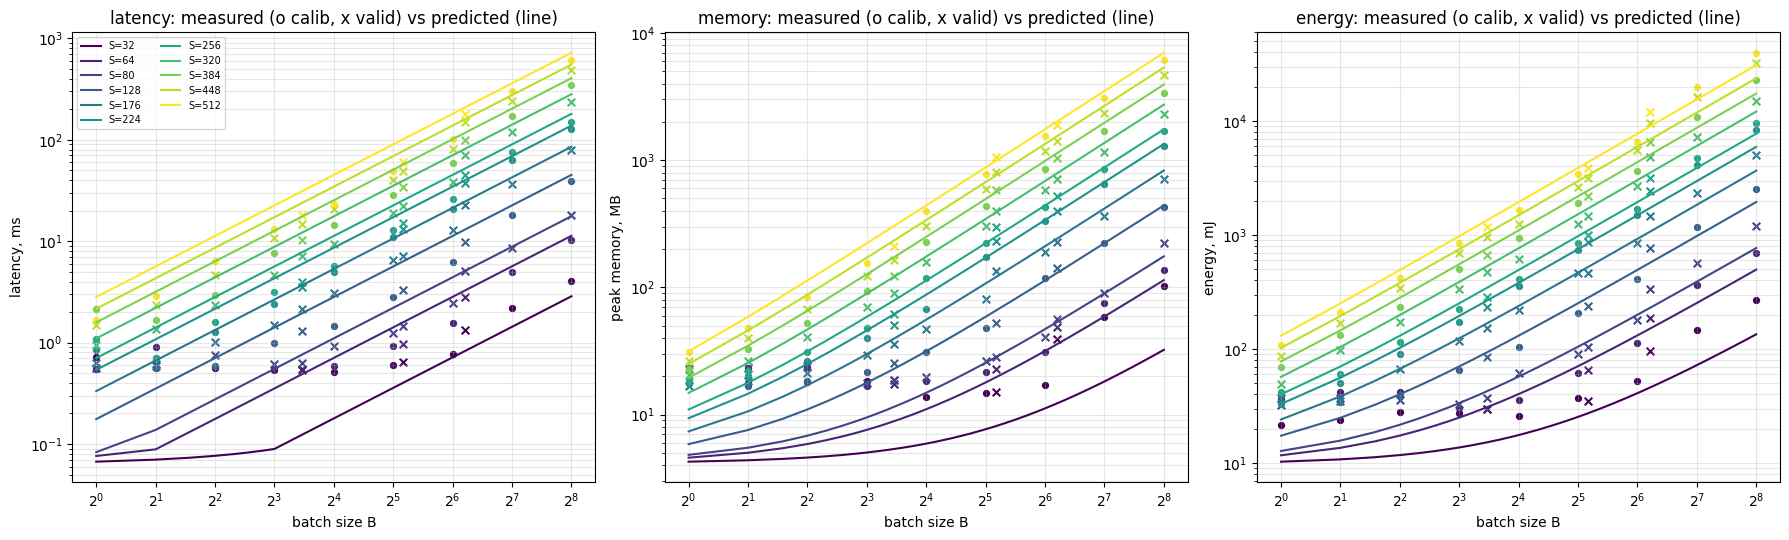

In [20]:
import matplotlib.pyplot as plt

theta = calibrate_theta(df_to_calibrate)
theta_energy = calibrate_theta_energy(df_to_calibrate)

d = df[df['memory'].astype(str) != 'OOM'].copy()
d['memory'] = d['memory'].astype(float)
d['is_validation'] = d['is_validation'].astype(bool)

B_line = np.arange(1, 257)
panels = [
    ('latency', 'latency, ms', 1e3, lambda S, B: latency(S, B, theta)),
    ('memory', 'peak memory, MB', 1e-6, memory),
    ('energy', 'energy, mJ', 1e3, lambda S, B: energy(S, B, theta_energy)),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (col, ylabel, k, pred) in zip(axes, panels):
    for i, S in enumerate(all_image_sizes):
        c = plt.cm.viridis(i / (len(all_image_sizes) - 1))
        g = d[d['S'] == S]
        ax.plot(B_line, pred(S, B_line) * k, color=c, label=f'S={S}')
        ax.scatter(g.loc[~g['is_validation'], 'B'], g.loc[~g['is_validation'], col] * k, color=c, marker='o', s=18)
        ax.scatter(g.loc[g['is_validation'], 'B'], g.loc[g['is_validation'], col] * k, color=c, marker='x', s=30)
    ax.set_xscale('log', base=2)
    ax.set_yscale('log')
    ax.set_xlabel('batch size B')
    ax.set_ylabel(ylabel)
    ax.set_title(f'{col}: measured (o calib, x valid) vs predicted (line)')
    ax.grid(True, which='both', alpha=0.3)
axes[0].legend(fontsize=7, ncol=2)
fig.tight_layout()
os.makedirs('results/figures', exist_ok=True)
fig.savefig('results/figures/predicted_vs_measured.png', dpi=150)
plt.show()

# Пояснения по графикам
По х - размер батча, по у - замеряемые метрики \
кружки - замеры на калибровке, крестики - замеры на валидации \
линии - рассчитанные по формулам значения



In [21]:
torch.cuda.get_device_properties()

_CudaDeviceProperties(name='Tesla T4', major=7, minor=5, total_memory=14912MB, multi_processor_count=40, uuid=050b5519-8dfc-7f8d-1a9b-0bcd7dec7443, pci_bus_id=0, pci_device_id=4, pci_domain_id=0, L2_cache_size=4MB)

# Мы так и не поймали out_of_memory

У GPU total_memory = 14912 MB, поэтому по формуле можно посчитать, на какой конфигурации мы сломаемся.
Зафиксируем B = 256 и найдём размер изображения $S$, кратный 16, при котором память превысит объём GPU:

$$
4\left(1\,039\,968 + B\left(26\,S^{2} + 868\right)\right) > 14\,912 \cdot 10^{6}
$$

$$
S > \sqrt{\frac{14\,912 \cdot 10^{6}/4 - 1\,039\,968 - 868\,B}{26\,B}}
  = \sqrt{\frac{3\,726\,737\,824}{6\,656}} \approx 748.3
$$

Округляем вверх до кратного 16:

$$
S = 16 \left\lceil \frac{748.3}{16} \right\rceil = 752
$$

Проверка: $\text{Memory}(736, 256) \approx 14\,427$ MB $< 14\,912$ MB, а $\text{Memory}(752, 256) \approx 15\,061$ MB $> 14\,912$ MB.

In [27]:
for image_size, batch in [(s, 256) for s in (512, 640, 736, 752, 896, 1024, 1072, 1200)]:
    image_size, batch = int(image_size), int(batch)
    x = None
    try:
        x = torch.randn(batch, 3, image_size, image_size, device=device)
        torch.cuda.reset_peak_memory_stats()
        with torch.inference_mode():
            model(x)
        torch.cuda.synchronize()
        mem = torch.cuda.max_memory_allocated()
        print(f"S={image_size:4d} B={batch:3d}  mem={mem/1e6:.0f}MB  pred={memory(image_size, batch)/1e6:.0f}MB")
    except torch.cuda.OutOfMemoryError:
        print(f"S={image_size:4d} B={batch:3d}  OOM  pred={memory(image_size, batch)/1e6:.0f}MB")
    finally:
        del x
        torch.cuda.empty_cache()

S= 512 B=256  mem=6168MB  pred=6984MB
S= 640 B=256  mem=9172MB  pred=10910MB
S= 736 B=256  mem=12334MB  pred=14427MB
S= 752 B=256  mem=12553MB  pred=15061MB
S= 896 B=256  mem=13988MB  pred=21379MB
S=1024 B=256  OOM  pred=27922MB
S=1072 B=256  OOM  pred=30601MB
S=1200 B=256  OOM  pred=38344MB


В итоге мы получили, что OOM получился позже, чем мы предсказывали. Это случилось тк мы сделали достаточно грубую прикидку, просуммировав все активации и веса одновременно. Когда я искал причину, я увидел, что в инференс моде выход слоя высвобождается, как только следующий его прочитал. Также мы не учитывали поправку на workspace cudnn в своих расчетах, что тоже сыграло свою роль.